# <center> Feature Engineering </center>

In [1]:
import pandas as pd
import numpy as np
import sys
sys.path.append("../../src")

from credit_scoring.iv import calcular_iv, iv_contagem, classificar_iv

In [2]:
# CARREGANDO O DATASET
df = pd.read_csv("../../data/processed/credit_processed.csv")
print(f"Dataset carregado: {df.shape}")

Dataset carregado: (149999, 13)


In [3]:
display(df)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,flag_missing_income,flag_missing_dependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0,0,0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0,0,0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0,0,0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0,0,0
4,0,0.907239,49,1,0.024926,23000.0,7,0,1,0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
149994,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0,0,0
149995,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0,0,0
149996,0,0.246044,58,0,1.402358,5400.0,18,0,1,0,0.0,1,0
149997,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0,0,0


In [4]:
# CRIANDO FEATURES BINÁRIAS PARA ATRASOS DE PAGAMENTO

df['teve_atraso_90dias'] = (df["NumberOfTimes90DaysLate"] > 0).astype(int)
df['teve_atraso_60dias'] = (df['NumberOfTime60-89DaysPastDueNotWorse'] > 0).astype(int)
df['teve_atraso_30dias'] = (df['NumberOfTime30-59DaysPastDueNotWorse'] > 0).astype(int)

In [5]:
# VERIFICANDO
for col in ['teve_atraso_90dias', 'teve_atraso_60dias', 'teve_atraso_30dias']:
    taxa = df.groupby(col)['SeriousDlqin2yrs'].mean()
    print(f"\n{col}:")
    print(taxa.round(3))


teve_atraso_90dias:
teve_atraso_90dias
0    0.046
1    0.416
Name: SeriousDlqin2yrs, dtype: float64

teve_atraso_60dias:
teve_atraso_60dias
0    0.051
1    0.364
Name: SeriousDlqin2yrs, dtype: float64

teve_atraso_30dias:
teve_atraso_30dias
0    0.040
1    0.208
Name: SeriousDlqin2yrs, dtype: float64


In [6]:
# CRIANDO UMA FEATURE CHAMADA "TOTAL_ATRASOS" (SOMANDO OS ATRASOS DE 30, 60 E 90 DIAS)
df['total_atrasos'] = (df['NumberOfTimes90DaysLate'] + df['NumberOfTime60-89DaysPastDueNotWorse'] + df['NumberOfTime30-59DaysPastDueNotWorse'])

In [7]:
# CRIANDO UMA FEATURE PARA QUALQUER TIPO DE ATRASO
df['teve_qualquer_atraso'] = (df['total_atrasos'] > 0).astype(int)

In [8]:
# VERIFICANDO A DISTRIBUIÇÃO
print("\n=== total_atrasos — distribuição ===")
print(df["total_atrasos"].describe().round(2))
print(f"\nTaxa inadimplência — sem atraso: "
      f"{df[df['teve_qualquer_atraso']==0]['SeriousDlqin2yrs'].mean():.2%}")
print(f"Taxa inadimplência — com atraso: "
      f"{df[df['teve_qualquer_atraso']==1]['SeriousDlqin2yrs'].mean():.2%}")


=== total_atrasos — distribuição ===
count    149999.00
mean          0.93
std          12.47
min           0.00
25%           0.00
50%           0.00
75%           0.00
max         294.00
Name: total_atrasos, dtype: float64

Taxa inadimplência — sem atraso: 2.73%
Taxa inadimplência — com atraso: 22.27%


In [9]:
# CRIANDO FEATURES DE RAZÃO E INTENSIDADE

#RENDA PER CAPITA
df['renda_per_capita'] = df['MonthlyIncome'] / (df['NumberOfDependents'] + 1)

# EXPOSIÇÃO AO CRÉDITO IMOBILIÁRIO VS. TOTAL
df['proporcao_credito_imobiliario'] = np.where(
    df['NumberOfOpenCreditLinesAndLoans'] > 0,
    df['NumberRealEstateLoansOrLines'] / df['NumberOfOpenCreditLinesAndLoans'],0
)

print("\n --- Renda Per Capita - Estatisticas ---")
print(df['renda_per_capita'].describe().round(2))


 --- Renda Per Capita - Estatisticas ---
count    149999.00
mean       4422.38
std        3180.16
min           0.00
25%        2151.00
50%        4000.00
75%        5400.00
max       23000.00
Name: renda_per_capita, dtype: float64


In [10]:
# SCORE DE RISCO SIMPLES (FEATURES DE INTERAÇÃO)

# Normalizando cada componente entre 0 e 1 antes de combinar

def normalizar(serie):
    return (serie - serie.min()) / (serie.max() - serie.min())

In [11]:
# APLICANDO A FUNÇÃO

df['score_risco'] = (
    0.5 * normalizar(df['RevolvingUtilizationOfUnsecuredLines']) +
    0.3 * normalizar(df['NumberOfTimes90DaysLate']) +
    0.2 * normalizar(df['total_atrasos'])
)

print("\n--- Score de Risco - Estatisticas ---")
print(df['score_risco'].describe().round(4))
print(f"\nCorrelação entre score de risco e inadimplência: "
      f"{df['score_risco'].corr(df['SeriousDlqin2yrs']):.4f}")


--- Score de Risco - Estatisticas ---
count    149999.0000
mean          0.1481
std           0.1648
min           0.0000
25%           0.0138
50%           0.0708
75%           0.2564
max           0.9575
Name: score_risco, dtype: float64

Correlação entre score de risco e inadimplência: 0.2896


In [12]:
# VALIDANDO O PODER PREDITIVO DAS NOVAS FEATURES

# Validação de IV — features originais vs features criadas
print("=== IV features binárias criadas ===")
for col in ["teve_atraso_90dias", "teve_atraso_60dias",
            "teve_atraso_30dias", "teve_qualquer_atraso"]:
    iv = calcular_iv(df, col, "SeriousDlqin2yrs", bins=2)
    print(f"{col}: {iv:.4f} — {classificar_iv(iv)}")

print("\n=== IV features de razão criadas ===")
for col in ["renda_per_capita", "proporcao_credito_imobiliario", "score_risco"]:
    iv = calcular_iv(df, col, "SeriousDlqin2yrs")
    print(f"{col}: {iv:.4f} — {classificar_iv(iv)}")

print("\n=== Comparação original vs criada ===")
comparacao = {
    "NumberOfTimes90DaysLate (original)": iv_contagem(df, "NumberOfTimes90DaysLate", "SeriousDlqin2yrs"),
    "teve_atraso_90dias (criada)": calcular_iv(df, "teve_atraso_90dias", "SeriousDlqin2yrs", bins=2),
    "MonthlyIncome (original)": calcular_iv(df, "MonthlyIncome", "SeriousDlqin2yrs"),
    "renda_per_capita (criada)": calcular_iv(df, "renda_per_capita", "SeriousDlqin2yrs"),
}
for feature, iv in comparacao.items():
    print(f"{feature}: {iv:.4f}")

=== IV features binárias criadas ===
teve_atraso_90dias: 0.8375 — Suspeito (investigar leakage)
teve_atraso_60dias: 0.5724 — Suspeito (investigar leakage)
teve_atraso_30dias: 0.6652 — Suspeito (investigar leakage)
teve_qualquer_atraso: 1.1755 — Suspeito (investigar leakage)

=== IV features de razão criadas ===
renda_per_capita: 0.0963 — Médio
proporcao_credito_imobiliario: 0.0485 — Médio
score_risco: 1.1133 — Suspeito (investigar leakage)

=== Comparação original vs criada ===


NumberOfTimes90DaysLate (original): 0.8774
teve_atraso_90dias (criada): 0.8375
MonthlyIncome (original): 0.0670
renda_per_capita (criada): 0.0963


## IV com optimal binning

O IV acima discretiza as variáveis contínuas em **quantis fixos** (10 faixas de mesmo tamanho). O **optimal binning**
(`optbinning`) escolhe os cortes que **maximizam o IV** com restrições de negócio:

- taxa de inadimplência **monotônica** ao longo das faixas (o risco só sobe ou só desce — faixas explicáveis);
- cada faixa com pelo menos **1% da base** (robustez estatística, sem faixas ruidosas);
- variáveis de contagem concentradas em zero (atrasos) com **cortes de negócio fixos**: 0, 1, 2, 3+;
- flags 0/1 tratadas como categóricas.

É a técnica padrão em modelos de risco (scorecards). A função vem de `credit_scoring.binning` — a mesma usada
no pipeline de produção para a análise bivariada e para as faixas do monitoramento de PSI.

In [13]:
import warnings
import matplotlib.pyplot as plt
from credit_scoring.binning import analise_binning, plot_lift

# avisos do prebinning por quantis (faixas vazias em variáveis concentradas em zero) — esperados
warnings.filterwarnings("ignore", category=UserWarning)

candidatas = [c for c in df.columns if c != "SeriousDlqin2yrs"]
bivariadas, ranking_ob = analise_binning(df, candidatas, "SeriousDlqin2yrs")

# Comparação com o IV por quantis (calcular_iv / iv_contagem)
contagem = ["NumberOfTimes90DaysLate", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTime30-59DaysPastDueNotWorse"]
iv_quantis = {c: (iv_contagem(df, c, "SeriousDlqin2yrs") if c in contagem else calcular_iv(df, c, "SeriousDlqin2yrs"))
              for c in candidatas}
ranking_ob["iv_quantis"] = ranking_ob["variavel"].map(iv_quantis)
ranking_ob["n_faixas"] = ranking_ob["variavel"].map(lambda v: len(bivariadas[v]))

print("=== IV com optimal binning × IV por quantis ===")
print(ranking_ob[["variavel", "iv", "iv_quantis", "n_faixas", "classificacao"]].round(4).to_string(index=False))

=== IV com optimal binning × IV por quantis ===
                            variavel     iv  iv_quantis  n_faixas                 classificacao
                       total_atrasos 1.4202      1.0504         4 Suspeito (investigar leakage)
                teve_qualquer_atraso 1.1755      1.1755         2 Suspeito (investigar leakage)
                         score_risco 1.0687      1.1133         5 Suspeito (investigar leakage)
RevolvingUtilizationOfUnsecuredLines 1.0579      1.1134         4 Suspeito (investigar leakage)
             NumberOfTimes90DaysLate 0.8774      0.8774         4 Suspeito (investigar leakage)
                  teve_atraso_90dias 0.8375      0.8375         2 Suspeito (investigar leakage)
NumberOfTime30-59DaysPastDueNotWorse 0.7552      0.7552         4 Suspeito (investigar leakage)
                  teve_atraso_30dias 0.6652      0.6652         2 Suspeito (investigar leakage)
NumberOfTime60-89DaysPastDueNotWorse 0.6000      0.6000         4 Suspeito (investigar l

### Tabela bivariada e lift por faixa

Para cada faixa: volume (`qtd`, `pct_total`), taxa de inadimplência, **odds** (inadimplentes por adimplente),
WoE, contribuição para o IV e **lift** (taxa da faixa ÷ taxa média da base).

In [14]:
for var in ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio"]:
    print(f"\n=== {var} ===")
    print(bivariadas[var][["faixa", "qtd", "pct_total", "taxa_evento", "odds", "woe", "iv", "lift"]].round(3).to_string(index=False))


=== RevolvingUtilizationOfUnsecuredLines ===
          faixa   qtd  pct_total  taxa_evento  odds    woe    iv  lift
1. (-inf, 0.08) 59999        0.4        0.018 0.018 -1.364 0.427 0.269
2. [0.08, 0.27) 30000        0.2        0.029 0.030 -0.867 0.104 0.437
3. [0.27, 0.70) 30000        0.2        0.070 0.076  0.053 0.001 1.051
 4. [0.70, inf) 30000        0.2        0.199 0.248  1.242 0.526 2.974

=== age ===
            faixa   qtd  pct_total  taxa_evento  odds    woe    iv  lift
 1. (-inf, 39.00) 29016      0.193        0.106 0.119  0.509 0.063 1.593
2. [39.00, 48.00) 29721      0.198        0.086 0.094  0.274 0.017 1.288
3. [48.00, 56.00) 29257      0.195        0.074 0.080  0.105 0.002 1.103
4. [56.00, 65.00) 30812      0.205        0.047 0.049 -0.380 0.025 0.699
  5. [65.00, inf) 31193      0.208        0.025 0.026 -1.024 0.143 0.375

=== DebtRatio ===
          faixa   qtd  pct_total  taxa_evento  odds    woe    iv  lift
1. (-inf, 0.13) 29999        0.2        0.061 0.065 -0.098

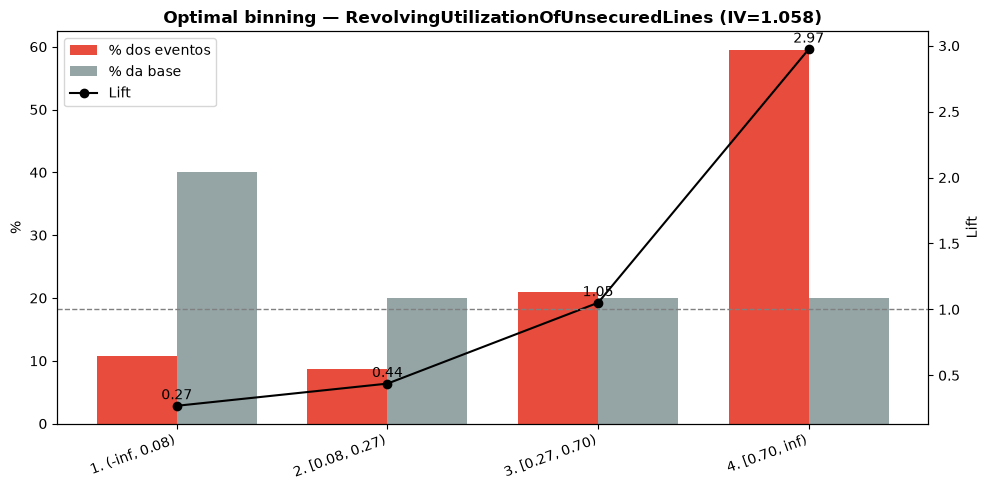

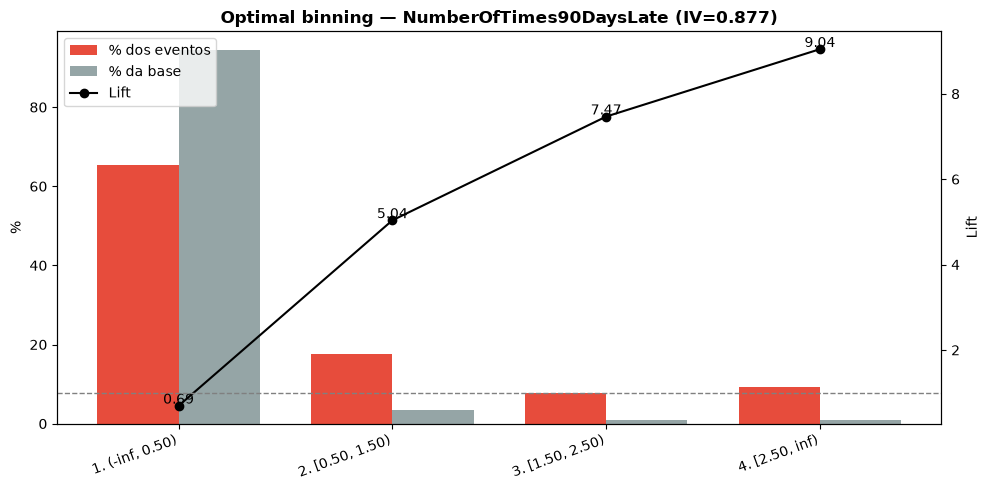

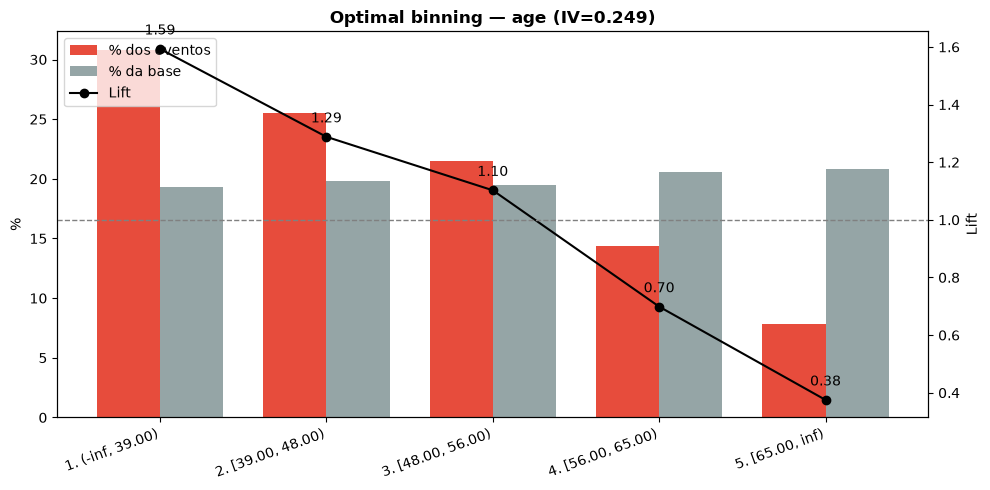

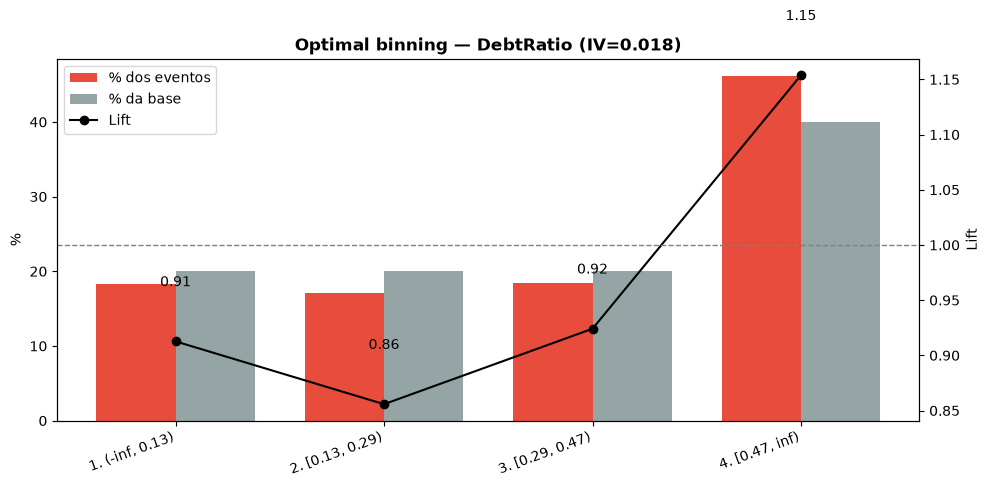

In [15]:
for var in ["RevolvingUtilizationOfUnsecuredLines", "NumberOfTimes90DaysLate", "age", "DebtRatio"]:
    fig = plot_lift(bivariadas[var])
    plt.show()

### Leitura do optimal binning

**O ranking confirma a seleção de features**, com quatro achados:

1. **Contagens de atraso e flags 0/1 têm o mesmo IV nos dois métodos** — as faixas de negócio (0, 1, 2, 3+) já eram as
   do `iv_contagem`, e uma flag só tem um corte possível.
2. **`total_atrasos` sobe de 1,05 para 1,42.** Com ~94% de zeros, os quantis fixos colapsam quase tudo numa faixa; as
   faixas de negócio do optimal binning separam muito melhor o risco. Reforça manter a feature criada.
3. **`NumberRealEstateLoansOrLines` sobe de 0,012 (fraco) para 0,045 (médio).** A relação é em **U**: o risco é maior para
   quem não tem financiamento imobiliário (lift 1,24), menor com exatamente um (0,79) e volta a subir com dois ou mais
   (0,94) — um padrão que os quantis fixos não capturavam. Ainda assim foi mantida fora:
   o IV segue baixo e a informação é redundante com `NumberOfOpenCreditLinesAndLoans`. É um candidato natural para
   uma próxima versão do modelo.
4. **`DebtRatio` cai para 0,019 (fraco)** e a taxa de inadimplência é quase plana nas faixas — reflexo do dado
   corrompido para quem não informou renda (visto no EDA). Foi mantido por ser a variável de comprometimento de renda,
   importante para a explicação de negócio, mas tem baixo poder isolado.

As tabelas mostram ainda a **ordenação monotônica do risco**: em `RevolvingUtilization`, os 20% que usam mais de 70%
do limite têm **lift de 2,97** (quase 3× a taxa média), enquanto os 40% que usam menos de 8% têm lift de 0,27; em
`age`, o risco cai continuamente de lift 1,59 (até 38 anos) para 0,38 (65+).

In [16]:
# ══════════════════════════════════════════════════════════════════════════════
# DECISÃO FINAL DE FEATURES — CRITÉRIOS E JUSTIFICATIVAS
# ══════════════════════════════════════════════════════════════════════════════
#
# Critérios de seleção aplicados (em ordem de prioridade):
#   1. Poder preditivo (IV > 0.02)
#   2. Disponibilidade em produção (feature existe no momento da concessão)
#   3. Ausência de redundância severa (correlação > 0.7 entre features)
#   4. Interpretabilidade de negócio (explicável para o comitê de crédito)
#
# ──────────────────────────────────────────────────────────────────────────────
# FEATURES MANTIDAS
# ──────────────────────────────────────────────────────────────────────────────
#
# [IV 1.11] RevolvingUtilizationOfUnsecuredLines
#   → Feature mais preditiva do dataset. Representa o comportamento atual
#     do cliente com crédito rotativo. Padrão monotônico confirmado na EDA.
#     Sem evidência de leakage — é uma medida do momento da análise.
#
# [IV 0.88] NumberOfTimes90DaysLate
#   → Sinal mais grave de comportamento histórico. WoE mostrou que um único
#     atraso de 90 dias multiplica o risco por 9x. Mantida a contagem original
#     pois captura a severidade (1x vs 3x atrasos), não apenas a ocorrência.
#
# [IV 0.84] teve_atraso_90dias (criada)
#   → Binarização de NumberOfTimes90DaysLate. Complementa a contagem original:
#     enquanto a contagem captura severidade, o binário captura a ocorrência
#     com sinal mais limpo. Modelos lineares se beneficiam do binário;
#     modelos de árvore extraem o melhor das duas representações.
#
# [IV 1.18] teve_qualquer_atraso (criada)
#   → Agrega os três tipos de atraso em um único sinal binário. Captura
#     o perfil geral de inadimplente histórico independente da janela de tempo.
#     IV alto é herdado da combinação de três features fortes — não é leakage.
#
# [IV 0.76] NumberOfTime30-59DaysPastDueNotWorse
#   → Atrasos leves têm dinâmica diferente dos atrasos graves. Um cliente
#     pode ter muitos atrasos de 30 dias sem nunca chegar a 90 dias —
#     perfil de risco distinto que o modelo precisa aprender separadamente.
#
# [IV 0.60] NumberOfTime60-89DaysPastDueNotWorse
#   → Janela intermediária de atraso. Complementa as outras duas janelas
#     para o modelo capturar a trajetória de deterioração do cliente.
#
# [IV 0.75] total_atrasos (criada)
#   → Soma das três janelas de atraso. Captura a exposição histórica total
#     ao risco, independente da janela. Feature de intensidade agregada.
#
# [IV 1.11] score_risco (criada)
#   → Índice composto ponderado pelos sinais mais fortes (RevolvingUtilization,
#     NumberOfTimes90DaysLate, total_atrasos). Entregamos ao modelo um sinal
#     pré-processado — ele decide se agrega valor além das features individuais.
#
# [IV 0.26] age
#   → Única feature demográfica com poder preditivo forte. Relação monotônica
#     confirmada na EDA: inadimplência cai consistentemente com a idade.
#     Não correlacionada com as features de comportamento — adiciona dimensão
#     independente ao modelo.
#
# [IV 0.097] renda_per_capita (criada)
#   → Supera MonthlyIncome isolado (IV 0.067) ao incorporar o número de
#     dependentes. Renda de R$5.000 para uma pessoa é diferente de R$5.000
#     para uma família de 5. Feature de negócio com justificativa clara.
#
# [IV 0.067] MonthlyIncome
#   → Mantida junto com renda_per_capita pois captura a capacidade absoluta
#     de pagamento, enquanto renda_per_capita captura a relativa. O modelo
#     pode extrair sinais distintos das duas representações.
#
# [IV 0.067] NumberOfOpenCreditLinesAndLoans
#   → Exposição total ao sistema de crédito. Cliente com muitas linhas abertas
#     tem maior risco de comprometimento de renda — sinal independente das
#     features de atraso.
#
# [IV 0.025] DebtRatio
#   → IV médio-baixo, mas representa o comprometimento de renda — conceito
#     central em análise de crédito. Mantida apesar do problema de qualidade
#     identificado na EDA (winsorização contextual aplicada).
#
# [IV 0.025] NumberOfDependents
#   → IV limítrofe, mas mantida por relevância de negócio. Número de
#     dependentes afeta a capacidade de pagamento e já está incorporada
#     em renda_per_capita — o modelo decide se há sinal adicional.
#
# [IV 0.008] flag_missing_income
#   → IV fraco isoladamente, mas representa um segmento real do mercado
#     (autônomos, aposentados sem contracheque). Confirmado na EDA que
#     o missing não é aleatório — carrega informação de perfil do cliente.
#
# ──────────────────────────────────────────────────────────────────────────────
# FEATURES DESCARTADAS
# ──────────────────────────────────────────────────────────────────────────────
#
# [IV 0.012] NumberRealEstateLoansOrLines
#   → IV fraco. Altamente correlacionada com NumberOfOpenCreditLinesAndLoans
#     que já está no modelo. Redundância sem ganho preditivo adicional.
#
# [IV 0.057] teve_atraso_60dias (criada)
#   → Redundante com teve_atraso_90dias e teve_qualquer_atraso que já estão
#     no modelo. Adicionar a versão de 60 dias aumenta dimensionalidade
#     sem ganho marginal de informação.
#
# [IV 0.067] teve_atraso_30dias (criada)
#   → Mesma justificativa de teve_atraso_60dias. A janela de 30 dias já
#     está representada por NumberOfTime30-59DaysPastDueNotWorse e
#     teve_qualquer_atraso.
#
# [IV 0.049] proporcao_credito_imobiliario (criada)
#   → IV médio-baixo. Correlacionada com NumberOfOpenCreditLinesAndLoans
#     e NumberRealEstateLoansOrLines. Não agrega dimensão nova ao modelo.
#
# [IV 0.004] flag_missing_dependents
#   → IV desprezível. O padrão de missing em dependentes está capturado
#     por flag_missing_income (93% de sobreposição identificada na EDA).
#
# ══════════════════════════════════════════════════════════════════════════════

In [17]:
# Decisão final de features para modelagem
# Critério: IV > 0.02 + sem redundância severa + disponível em produção

features_modelo = [
    # Features originais validadas
    "RevolvingUtilizationOfUnsecuredLines",  # IV 1.11 — mais forte do dataset
    "NumberOfTimes90DaysLate",               # IV 0.88 — histórico grave
    "NumberOfTime30-59DaysPastDueNotWorse",  # IV 0.76 — histórico leve
    "NumberOfTime60-89DaysPastDueNotWorse",  # IV 0.60 — histórico moderado
    "age",                                   # IV 0.26 — perfil demográfico
    "MonthlyIncome",                         # IV 0.07 — capacidade de pagamento
    "NumberOfOpenCreditLinesAndLoans",       # IV 0.07 — exposição ao crédito
    "DebtRatio",                             # IV 0.03 — comprometimento de renda
    "NumberOfDependents",                    # IV 0.02 — custo de vida
    "flag_missing_income",                   # IV 0.008 — padrão de missing informativo

    # Features criadas que agregam valor
    "renda_per_capita",                      # IV 0.096 — supera MonthlyIncome isolado
    "teve_atraso_90dias",                    # IV 0.84 — binarização do sinal mais forte
    "teve_qualquer_atraso",                  # IV 1.18 — agregado de comportamento
    "total_atrasos",                         # contagem agregada
    "score_risco",                           # índice composto para o modelo explorar
]

# Features descartadas e motivo
descartadas = {
    "NumberRealEstateLoansOrLines": "IV 0.012 — fraco, redundante com OpenCreditLines",
    "flag_missing_dependents": "IV 0.004 — fraco demais",
    "proporcao_credito_imobiliario": "IV 0.049 — médio mas correlacionado com features mantidas",
    "teve_atraso_30dias": "IV 0.67 — redundante com teve_atraso_90dias e total_atrasos",
    "teve_atraso_60dias": "IV 0.57 — redundante com teve_atraso_90dias e total_atrasos",
}

print("=== Features selecionadas para modelagem ===")
for f in features_modelo:
    print(f"  ✓ {f}")

print(f"\nTotal: {len(features_modelo)} features")

print("\n=== Features descartadas ===")
for f, motivo in descartadas.items():
    print(f"  ✗ {f} — {motivo}")

# Salvar dataset final para modelagem
X = df[features_modelo]
y = df["SeriousDlqin2yrs"]

X.to_csv("../../data/processed/X_features.csv", index=False)
y.to_csv("../../data/processed/y_target.csv", index=False)

print(f"\nX salvo: {X.shape}")
print(f"y salvo: {y.shape}")

=== Features selecionadas para modelagem ===
  ✓ RevolvingUtilizationOfUnsecuredLines
  ✓ NumberOfTimes90DaysLate
  ✓ NumberOfTime30-59DaysPastDueNotWorse
  ✓ NumberOfTime60-89DaysPastDueNotWorse
  ✓ age
  ✓ MonthlyIncome
  ✓ NumberOfOpenCreditLinesAndLoans
  ✓ DebtRatio
  ✓ NumberOfDependents
  ✓ flag_missing_income
  ✓ renda_per_capita
  ✓ teve_atraso_90dias
  ✓ teve_qualquer_atraso
  ✓ total_atrasos
  ✓ score_risco

Total: 15 features

=== Features descartadas ===
  ✗ NumberRealEstateLoansOrLines — IV 0.012 — fraco, redundante com OpenCreditLines
  ✗ flag_missing_dependents — IV 0.004 — fraco demais
  ✗ proporcao_credito_imobiliario — IV 0.049 — médio mas correlacionado com features mantidas
  ✗ teve_atraso_30dias — IV 0.67 — redundante com teve_atraso_90dias e total_atrasos
  ✗ teve_atraso_60dias — IV 0.57 — redundante com teve_atraso_90dias e total_atrasos



X salvo: (149999, 15)
y salvo: (149999,)
